# 9 · Capital mobility between sectors, in Portugal

Notebook 8 estimated the model's capital-mobility coefficient `μ` between EU countries, where net foreign financing measures the transfer of capital. The model's own departments are sectors, not countries, so this notebook asks the same question between the sectors of one economy: Portugal, 2000–2023, from Eurostat's annual accounts by industry.

**What in the data is the mobility term?** In the coupled model a department's capital grows by reinvesting its own surplus and by the mobility term,

`ΔCᵢ = σ_c Sᵢ − δCᵢ + μ (rᵢ − r̄) Cᵢ`,

and the mobility term sums to zero across departments: it moves capital, it does not create it. Sectors have no current account, so the transfer has to be built. Take net investment `Iᵢ − CFCᵢ` as the data's `ΔCᵢ`, and assume, as the model does, that every sector reinvests the same share of its surplus. That share is then the economy's own, `σ_c,t = Σᵢ(Iᵢₜ − CFCᵢₜ) / Σᵢ Sᵢₜ`, and what is left over,

`Rᵢₜ = (Iᵢₜ − CFCᵢₜ) − σ_c,t Sᵢₜ`,

is the capital a sector received beyond what its own surplus paid for. `Σᵢ Rᵢₜ = 0` by construction, like the model's term. The estimating equation is

`Rᵢₜ / Cᵢ,ₜ₋₁ = μ · (rᵢ,ₜ₋₁ − r̄ₜ₋₁) + error`,

with `C` the net capital stock at current replacement cost at the start of the year, `r = S/(C + V)` and `r̄` its `C`-weighted mean, as in `_mobility_flow`. Both sides are in percent.

The catch is visible already: the regressor and the own-financing term `σ_c S` are both built from the surplus `S`, so anything that mismeasures `S` moves both. Section 4 measures how much that matters.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, DataFrames, Statistics, LinearAlgebra, Random, Printf
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

In [2]:
"""Sections × years matrix of a column of the extract."""
grid(raw, col, secs, years) = [raw[(raw.section .== s) .& (raw.year .== y), col][1] for s in secs, y in years]

"""Remove unit means (sector effects), or unit and period means (two-way effects)."""
within(M) = M .- mean(M; dims = 2)
twoway(M) = M .- mean(M; dims = 2) .- mean(M; dims = 1) .+ mean(M)

"""OLS slope of y on x (both already demeaned), its classical standard error and the residuals."""
function slope(y, x; dof = length(y) - 1)
    b = dot(x, y) / dot(x, x)
    u = y .- b .* x
    return b, sqrt(sum(abs2, u) / dof / dot(x, x)), u
end

"""OLS of y on [1 x], returning the slope and its classical standard error."""
function ols(y, x)
    X = hcat(ones(length(x)), x)
    b = X \ y
    u = y - X * b
    return b[2], sqrt(inv(X'X)[2, 2] * sum(abs2, u) / (length(y) - 2))
end

"""Driscoll–Kraay standard error of a slope (x, u: N × T, x demeaned), Bartlett kernel:
robust to any correlation across sectors within a year and to serial correlation up to `L` years."""
function driscoll_kraay(x, u; L = 2)
    h = vec(sum(x .* u; dims = 1))
    S = sum(abs2, h) + 2 * sum((1 - l / (L + 1)) * sum(h[l+1:end] .* h[1:end-l]) for l in 1:L)
    return sqrt(S) / dot(x, x)
end

"""
The panel of the estimating equation for the sections `secs`. `self_employed = :imputed`
counts each self-employed worker at the average employee's compensation of the section
(`impute_self_employed`); `own = :lagged` nets own financing out of last year's surplus
instead of this year's. Returns the dependent variable `y` (% of C), the lagged gap `gap`
(pp), both sections × years, and the reinvestment share `σ` by year.
"""
function mobility_panel(raw, secs; self_employed = :excluded, own = :current)
    years = sort(unique(raw.year))
    g(col) = grid(raw, col, secs, years)
    V = g(:compensation)
    self_employed == :imputed && (V = V .* g(:employment) ./ g(:employees))
    S = g(:GVA) .- V .- g(:CFC)               # surplus value: business income net of CFC
    I = g(:GFCF) .- g(:CFC)                   # net investment
    K = g(:capital_stock)                     # end of year
    t = 3:length(years)                       # flows in t, stock at t-1, gap at t-1
    r = S[:, t .- 1] ./ (K[:, t .- 2] .+ V[:, t .- 1])
    r̄ = vec(sum(r .* K[:, t .- 2]; dims = 1) ./ sum(K[:, t .- 2]; dims = 1))
    Sown = own == :lagged ? S[:, t .- 1] : S[:, t]
    σ = vec(sum(I[:, t]; dims = 1) ./ sum(Sown; dims = 1))
    R = I[:, t] .- σ' .* Sown
    return (y = 100 .* R ./ K[:, t .- 1], gap = 100 .* (r .- r̄'), σ = σ, years = years[t],
            R = R, secs = secs)
end

"""Two-way (sector and year effects) estimate of μ: slope, classical and Driscoll–Kraay se."""
function mu_twoway(P; cols = axes(P.y, 2))
    Y, G = twoway(P.y[:, cols]), twoway(P.gap[:, cols])
    N, T = size(Y)
    b, se, u = slope(vec(Y), vec(G); dof = N * T - N - T)
    return b, se, driscoll_kraay(G, reshape(u, N, T))
end

"""K-weighted dispersion of the profit rates along a simulated path."""
function dispersion_path(sol, p)
    N = length(p.e)
    map(sol.u) do X
        C, V = X[1:N], X[N+1:2N]
        r = _io_profit_rates(C, V, p.e .* V, p)
        r̄ = sum(r .* C) / sum(C)
        sqrt(sum(C .* (r .- r̄) .^ 2) / sum(C))
    end
end

dispersion_path (generic function with 1 method)

## 1. The panel

The extract `data/eurostat_pt_sectors.csv` (built by `data/build_eurostat_pt_sectors.jl`; provenance in `data/eurostat_pt_sectors_PROVENANCE.md`) has the 19 NACE sections. Three are left out of the baseline: public administration, education and health (O, P, Q), whose output is mostly non-market, so neither their surplus nor their investment answers to a rate of profit. Real estate (L) is left out too: its value added is mostly the imputed rent of owner-occupied dwellings, and its capital stock is the housing stock. That leaves 15 market sectors.

In [3]:
raw = CSV.read(joinpath("..", "..", "data", "eurostat_pt_sectors.csv"), DataFrame)
ALL = sort(String.(unique(raw.section)))
MARKET = setdiff(ALL, ["L", "O", "P", "Q"])
P = mobility_panel(raw, MARKET)
@assert maximum(abs.(sum(P.R; dims = 1))) < 1e-6 * maximum(abs.(P.R))   # Σᵢ Rᵢₜ = 0
(sectors = length(MARKET), years = (first(P.years), last(P.years)))

(sectors = 15, years = (2002, 2023))

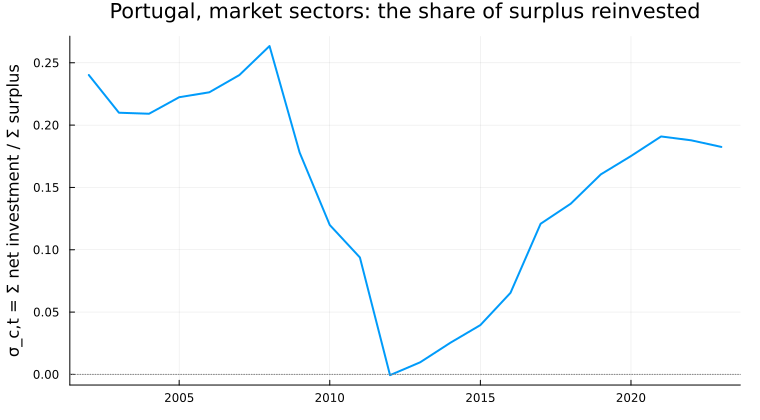

In [4]:
plot(P.years, P.σ, lw = 2, legend = false, ylabel = "σ_c,t = Σ net investment / Σ surplus",
     title = "Portugal, market sectors: the share of surplus reinvested")
hline!([0], color = :gray, ls = :dot)

Before 2008 the market sectors reinvested a fifth to a quarter of their surplus in net investment. After 2008 the share fell to zero by 2012 (gross investment barely covered depreciation), and it recovered to 0.18–0.19 by 2020. The common share changes every year, so own financing is netted out year by year, not with one constant `σ_c`.

## 2. Between sectors: the gaps do not attract capital

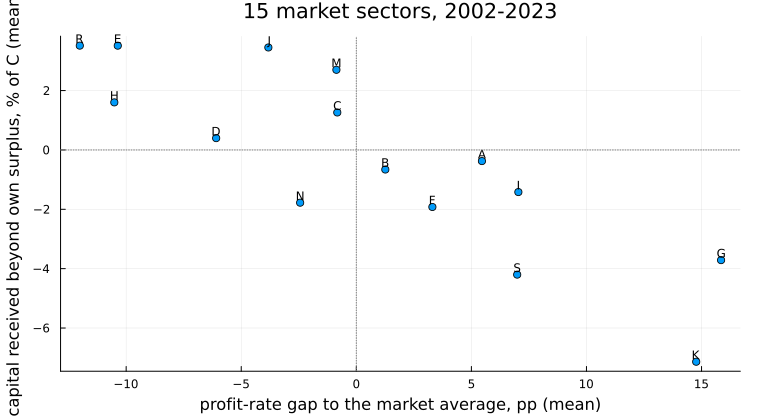

In [5]:
codes = P.secs
mean_gap, mean_y = vec(mean(P.gap; dims = 2)), vec(mean(P.y; dims = 2))
scatter(mean_gap, mean_y, series_annotations = text.(codes, 8, :bottom), legend = false,
        xlabel = "profit-rate gap to the market average, pp (mean)",
        ylabel = "capital received beyond own surplus, % of C (mean)",
        title = "15 market sectors, $(first(P.years))-$(last(P.years))")
hline!([0], color = :gray, ls = :dot); vline!([0], color = :gray, ls = :dot)

In [6]:
b_btw, se_btw = ols(mean_y, mean_gap)
@printf("between sectors   μ̂ = %6.3f  (se %.3f)\n", b_btw, se_btw)

between sectors   μ̂ = -0.312  (se 0.054)


**Between sectors the slope is negative, `μ̂` = −0.31** (standard error 0.05). The sectors with the highest measured profit rates, trade (G, 16 points above the average) and finance (K, 15 points), received the least capital beyond their own surplus, and low-profit sectors, water and waste (E), arts (R) and information and communication (J), received the most.

This is not capital fleeing profit. The model's departments share one technology for turning capital into output, and the data's sectors do not: trade and finance need little fixed capital per euro of surplus, and utilities and transport a great deal. A sector's permanent gap reflects its capital intensity, and what the accounts count as its capital and its surplus (the mixed income of shopkeepers in G, interest margins in K), more than a disequilibrium that capital chases. In a theory where competition equalizes rates of profit at prices of production, gaps that persist for twenty years are evidence about the measurement, not about `μ`. The between-sector slope does not estimate `μ`, which is why the within estimates below matter.

## 3. Within sectors, year to year

Sector effects absorb each sector's permanent gap, whatever its cause, and year effects absorb the common cycle in investment. What is left is whether a sector received more capital in the years its profit rate rose above its own norm.

In [7]:
b_fe, se_fe, _ = slope(vec(within(P.y)), vec(within(P.gap)); dof = length(P.y) - size(P.y, 1) - 1)
b_tw, se_tw, dk_tw = mu_twoway(P)
@printf("within sectors (sector effects)     μ̂ = %6.3f  (se %.3f)\n", b_fe, se_fe)
@printf("sector and year effects             μ̂ = %6.3f  (se %.3f, Driscoll-Kraay %.3f)\n", b_tw, se_tw, dk_tw)

within sectors (sector effects)     μ̂ =  0.109  (se 0.038)
sector and year effects             μ̂ =  0.106  (se 0.039, Driscoll-Kraay 0.052)


**With sector and year effects, `μ̂` = 0.11** (0.04; Driscoll–Kraay 0.05, robust to common shocks and to serial correlation): in the years a sector's profit rate rose above its own norm, it received more capital, about a third of the model's default speed. That is close to the within-country response before 2008 in notebook 8 (0.15).

## 4. How fragile is it?

Two choices enter both sides of the equation through the surplus `S`. **Own financing**: netting out this year's surplus or last year's. **The self-employed**: their income counts as surplus value as published, or they are counted at the average employee's compensation of their sector (`self_employed = :imputed`, as in notebooks 7 and 8). And the sample: with or without finance (K), whose profits are mostly interest margins.

In [8]:
rows = DataFrame(sample = String[], self_employed = Symbol[], own_financing = Symbol[],
                 μ = Float64[], se = Float64[], se_DK = Float64[])
for (lab, secs) in (("15 market sectors", MARKET), ("without finance (K)", setdiff(MARKET, ["K"]))),
    se_mode in (:excluded, :imputed), own in (:current, :lagged)
    b, se, dk = mu_twoway(mobility_panel(raw, secs; self_employed = se_mode, own = own))
    push!(rows, (lab, se_mode, own, round(b, digits = 3), round(se, digits = 3), round(dk, digits = 3)))
end
show(rows; allcols = true, summary = false, eltypes = false)

 Row │ sample               self_employed  own_financing  μ       se     se_DK 
─────┼─────────────────────────────────────────────────────────────────────────
   1 │ 15 market sectors    excluded       current         0.106  0.039  0.052
   2 │ 15 market sectors    excluded       lagged          0.067  0.038  0.058
   3 │ 15 market sectors    imputed        current        -0.194  0.058  0.08
   4 │ 15 market sectors    imputed        lagged         -0.261  0.055  0.083
   5 │ without finance (K)  excluded       current         0.097  0.04   0.053
   6 │ without finance (K)  excluded       lagged          0.038  0.039  0.059
   7 │ without finance (K)  imputed        current        -0.227  0.067  0.089
   8 │ without finance (K)  imputed        lagged         -0.348  0.064  0.098

**The estimate does not survive the self-employment adjustment.** Netting out last year's surplus instead of this year's lowers `μ̂` to 0.07 (0.04 without finance), indistinguishable from zero with Driscoll–Kraay errors. Imputing the self-employed turns it negative in every variant, from −0.19 to −0.35, and the Driscoll–Kraay errors (0.08–0.10) do not save it.

The reason is in the construction. Imputing a wage to the self-employed lowers the surplus of the sectors where they work. A lower `S` lowers the sector's gap, and it raises the capital the sector received beyond its own surplus, because `R = (I − CFC) − σ_c S` subtracts less. That is a negative relation built into the measure, and it gets stronger as `σ_c` rises (the imputation raises the average `σ_c` from 0.15 to 0.23, because the same net investment is divided by a smaller total surplus). Whatever mismeasures `S` biases `μ̂` in the same way, so the sign of the estimate depends on a measurement choice. Between countries, notebook 8 did not have this problem: the current account is measured independently of the profit rate.

## 5. Before and after 2008

In [9]:
for (label, cols) in (("2002-2008", findall(<=(2008), P.years)), ("2009-2023", findall(>(2008), P.years)))
    b, se, dk = mu_twoway(P; cols = cols)
    @printf("%s  sector and year effects  μ̂ = %6.3f  (se %.3f, Driscoll-Kraay %.3f)\n", label, b, se, dk)
end

2002-2008  sector and year effects  μ̂ = -0.109  (se 0.062, Driscoll-Kraay 0.050)
2009-2023  sector and year effects  μ̂ =  0.126  (se 0.059, Driscoll-Kraay 0.134)


**Before 2008, `μ̂` = −0.11** (Driscoll–Kraay 0.05): capital moved *against* the gap, toward sectors whose profit rate had fallen below their norm. This was also when Portugal received foreign financing at a profit rate below the EU27's (notebook 8, section 2): credit, not profitability, steered investment. **After 2008, `μ̂` = 0.13**, but its Driscoll–Kraay error is 0.13. Between countries the order was the other way round, 0.15 before and −0.27 after.

## 6. Back in the model

Portugal's 15 market sectors in 2019 as the model's departments (`C` the net stock, `V` compensation, `e = S/V` with the model's floor of 0.1, `δ = CFC/C`, the 2019 reinvestment share for every sector), in the coupled model with a random technical matrix, under the estimates above and the model's default.

μ = 0                                    dispersion at t = 0: 0.0669, t = 20: 0.0106
μ = 0.11: within sectors                 dispersion at t = 0: 0.0669, t = 20: 0.0092


μ = 0.3: default, ≈ between countries    dispersion at t = 0: 0.0669, t = 20: 0.0078


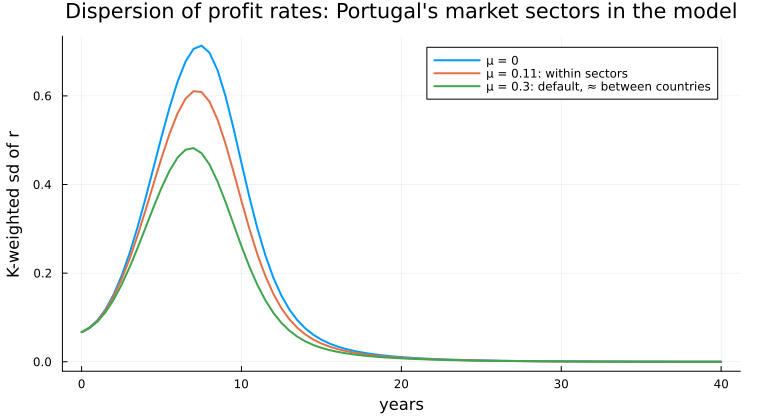

In [10]:
d19 = raw[raw.year .== 2019, :]
σ19 = P.σ[findfirst(==(2019), P.years)]
depts = map(MARKET) do s
    row = d19[d19.section .== s, :][1, :]
    S = row.GVA - row.compensation - row.CFC
    Department(String(s); c = row.capital_stock, v = row.compensation, e = max(S / row.compensation, 0.1),
               σ_c = σ19, σ_v = 0.1, δ = row.CFC / row.capital_stock)
end
plt = plot(xlabel = "years", ylabel = "K-weighted sd of r", legend = :topright,
           title = "Dispersion of profit rates: Portugal's market sectors in the model")
for (μ, lab) in ((0.0, "μ = 0"), (round(b_tw, digits = 2), "μ = $(round(b_tw, digits = 2)): within sectors"),
                 (0.3, "μ = 0.3: default, ≈ between countries"))
    sol, _, p = simulate_Ndept_custom(deepcopy(depts); T = 40.0, seed = 1, coupled = true, μ = μ)
    d = dispersion_path(sol, p)
    plot!(plt, sol.t, d, lw = 2, label = lab)
    @printf("%-40s dispersion at t = 0: %.4f, t = 20: %.4f\n", lab, d[1], d[findfirst(>=(20.0), sol.t)])
end
plt

The profit rates converge under every value, from a dispersion of 0.067 to 0.011 at year 20 with `μ` = 0, because the departments' own accumulation also equalizes them. Mobility speeds this up only a little: 0.009 with the within-sector 0.11 and 0.008 with 0.3. In the model, the gaps measured in the data close within two decades whatever `μ` is. In the data, the same gaps have persisted for twenty years, which is the point of section 2 again.

## What the data say about `μ` between sectors

- **Persistent sectoral gaps do not attract capital** (`μ̂` = −0.31 between sectors). They reflect capital intensity and what the accounts count as capital and surplus, not the disequilibrium the mobility term describes.
- **Year to year, a sector whose profit rate rises above its norm receives more capital**, at `μ̂` ≈ 0.1, a third of the default, *if* the income of the self-employed is counted as surplus value. Counted as wages, the sign flips, because surplus enters both sides of the equation.
- **Before 2008 capital moved against the gap**, as foreign credit financed the economy at profit rates below the EU27's.

So, unlike the between-country estimate of notebook 8, the between-sector `μ` is not identified by these data: sectors have no independent record of capital transferred, and building one from investment and surplus ties the estimate to how surplus is measured. Two things would help. One is a measure of transfers independent of `S`: the financial accounts by sector, or firm-level data on the financing of investment. The other is a panel of sectors in several countries, where year-by-country effects absorb national credit cycles like Portugal's.